
========== QUESTION 1 ==========

First 5 Records:
  Employee_ID  Department    Job_Role  Job_Level  Monthly_Income  \
0      E00000  Operations  Specialist          2         73628.0   
1      E00001     Finance  Specialist          4        118579.0   
2      E00002          HR  Specialist          3             NaN   
3      E00003  Operations    Engineer          4        108013.0   
4      E00004         R&D    Engineer          1         34166.0   

   Tenure_Years Overtime  Overtime_Hours  Satisfaction_Score  \
0          19.4      Yes              13                 3.7   
1           9.2       No              29                 2.3   
2          17.4      Yes               2                 1.2   
3           0.6      Yes              26                 1.9   
4          17.6      Yes               7                 4.0   

   Commute_Distance_Km Attrition  
0                 35.4        No  
1                 11.8        No  
2                 35.9        No  
3             

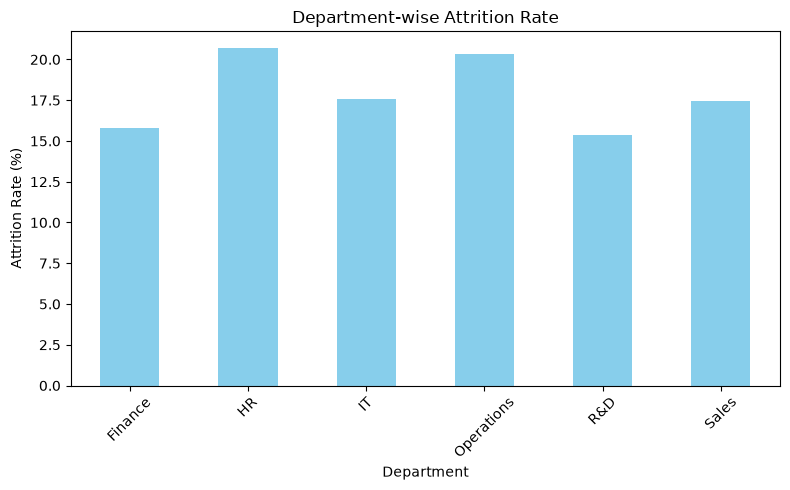


========== QUESTION 6 ==========

Average Income and Tenure Comparison:
           Monthly_Income  Tenure_Years
Attrition                              
No           99774.770169     10.685553
Yes          99998.807692      9.731624


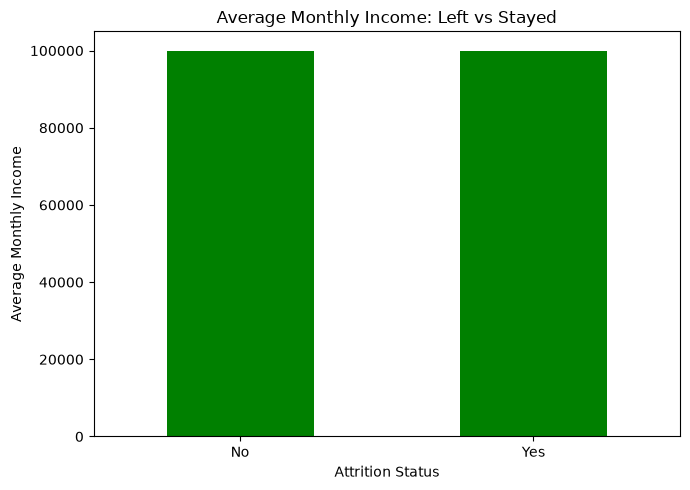

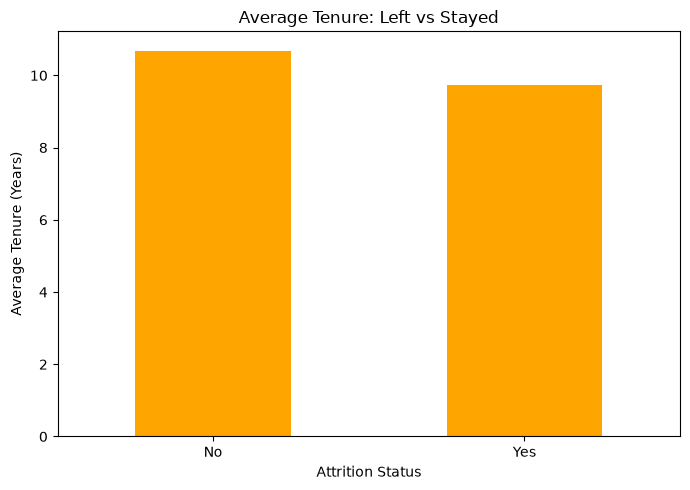


========== QUESTION 7 ==========

Attrition Rate by Overtime:
Attrition         No        Yes
Overtime                       
No         79.113924  20.886076
Yes        84.730539  15.269461


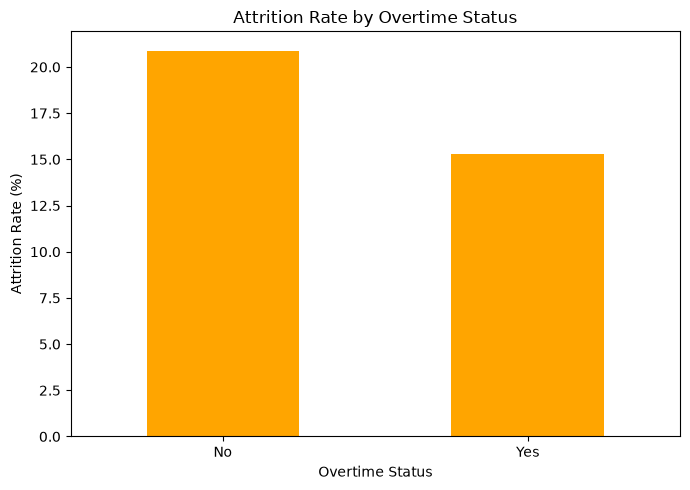


========== QUESTION 8 ==========

Average Satisfaction by Job Level:
Job_Level
1    3.079231
2    3.024409
3    2.944286
4    2.992701
5    3.110345
Name: Satisfaction_Score, dtype: float64

Average Satisfaction by Job Role:
Job_Role
Analyst       3.051220
Associate     2.991912
Engineer      3.080916
Manager       2.942520
Specialist    3.066917
Name: Satisfaction_Score, dtype: float64


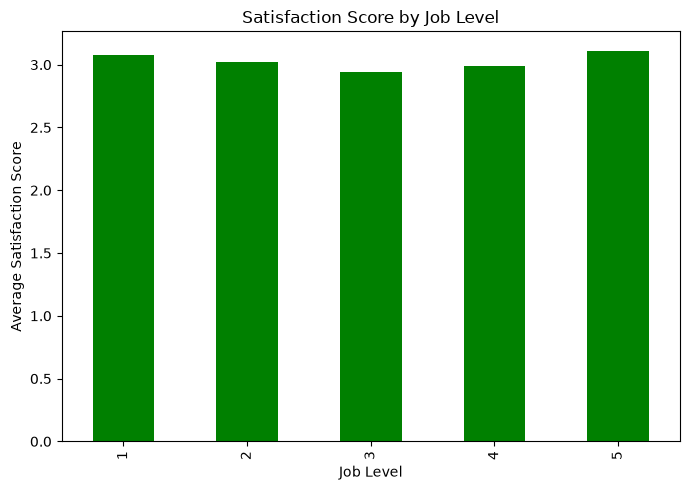

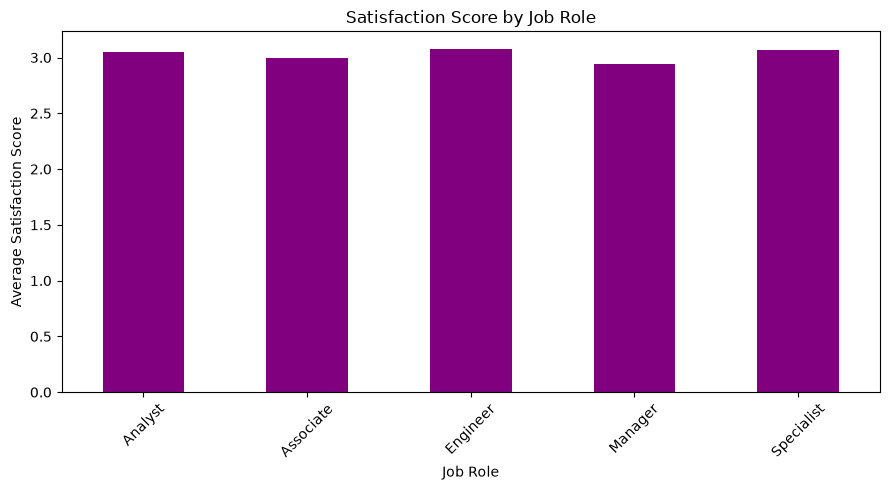


========== QUESTION 9 ==========

Attrition by Commute Distance:
Attrition             No        Yes
Distance_Band                      
0-10 km        80.000000  20.000000
10-20 km       83.211679  16.788321
20-30 km       84.172662  15.827338
30+ km         81.102362  18.897638


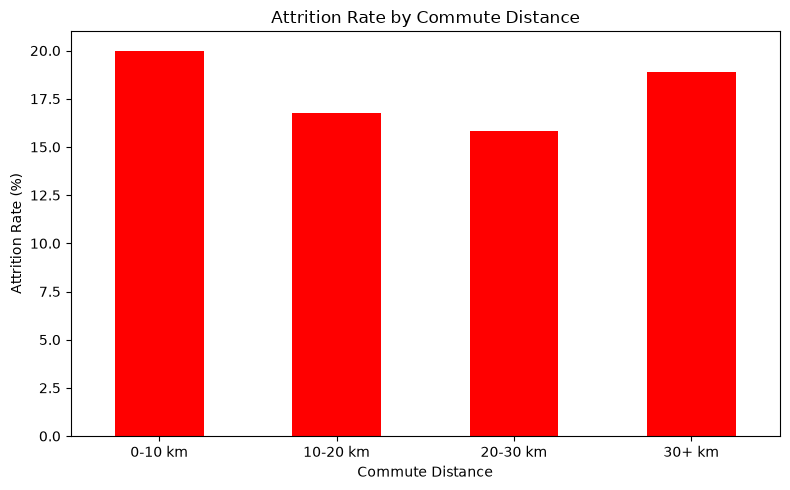


========== QUESTION 10 ==========

Departments Ranked by Average Overtime Hours:
Department
Finance       24.294737
HR            22.456897
R&D           22.326923
Operations    21.991525
Sales         21.990826
IT            20.074074
Name: Overtime_Hours, dtype: float64


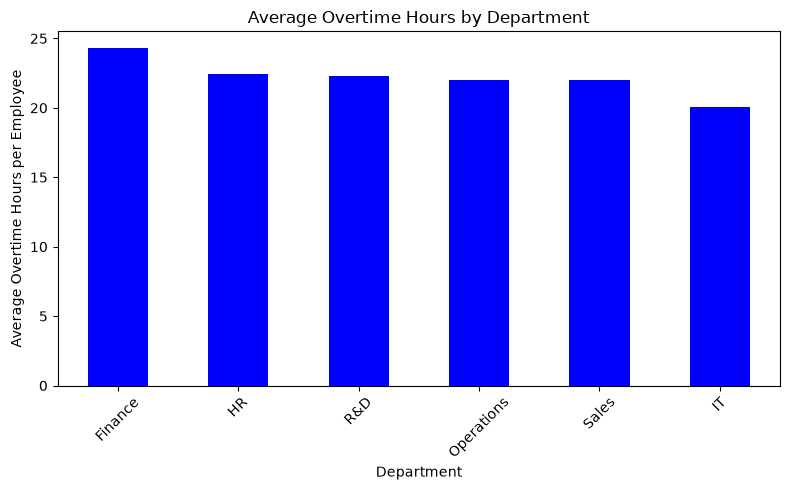


========== QUESTION 11 ==========
Mean Monthly Income: 99815.1
Median Monthly Income: 95049.5
Standard Deviation: 44764.8

========== QUESTION 12 ==========
Q1: 61232.0
Q3: 136744.0
IQR: 75512.0
Lower Limit: -52036.0
Upper Limit: 250012.0

Salary Outliers:
Empty DataFrame
Columns: [Employee_ID, Monthly_Income]
Index: []

Total Salary Outliers: 0


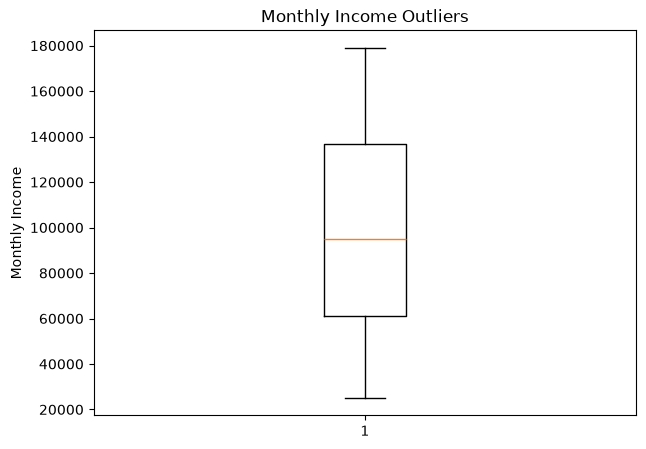


========== QUESTION 13 ==========

Attrition Across Tenure Bands:
Attrition                 No        Yes
Tenure_Band                            
Less than 2 years  81.818182  18.181818
2-5 years          83.529412  16.470588
5+ years           81.764706  18.235294

Attrition Rate by Tenure:
Tenure_Band
Less than 2 years    18.181818
2-5 years            16.470588
5+ years             18.235294
Name: Yes, dtype: float64


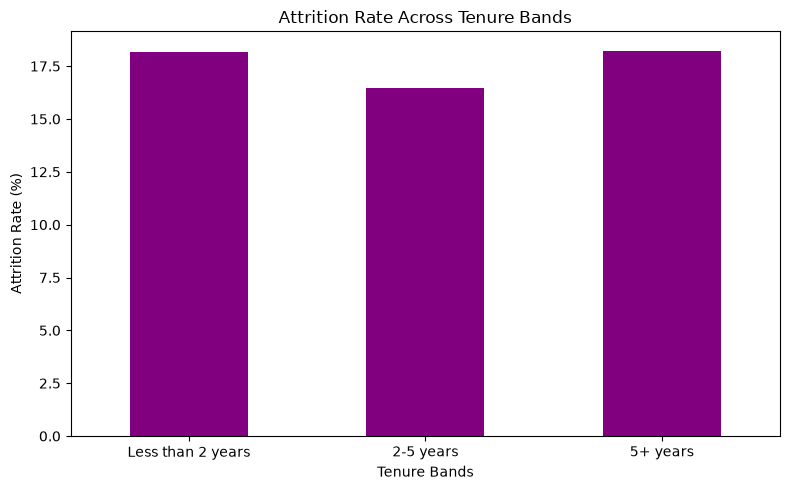


========== QUESTION 14 ==========

Department Summary Table:
            Headcount  Average_Salary  Employees_Left  Attrition_Rate
Department                                                           
Finance            95        91256.17              15           15.79
HR                116       101657.95              24           20.69
IT                108        99087.99              19           17.59
Operations        118       104975.98              24           20.34
R&D               104        97719.72              16           15.38
Sales             109       102446.20              19           17.43

Department Summary Saved Successfully!

========== QUESTION 15 ==========

ANALYSIS FINDINGS:
Highest Attrition Department: HR (20.69%)
Attrition with Overtime: 15.27 %
Attrition without Overtime: 20.89 %
Lowest Satisfaction Job Role: Manager (2.94)
Average Income of Employees Who Left: 99998.81
Average Income of Employees Who Stayed: 99774.77
Average Tenure of Employees Who

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load Dataset
df = pd.read_csv("17_hr_attrition.csv")


# ==================================================
# Q1. LOAD AND INSPECT THE EMPLOYEE DATASET
# ==================================================

print("\n========== QUESTION 1 ==========")

print("\nFirst 5 Records:")
print(df.head())

print("\nLast 5 Records:")
print(df.tail())

print("\nDataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nStatistical Summary:")
print(df.describe())


# ==================================================
# Q2. CHECK MISSING VALUES AND DUPLICATE EMPLOYEE IDs
# ==================================================

print("\n========== QUESTION 2 ==========")

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Employee IDs:")
print(df['Employee_ID'].duplicated().sum())

print("\nDuplicate Records:")
print(df[df['Employee_ID'].duplicated(keep=False)])


# ==================================================
# Q3. CLEAN MISSING VALUES
# ==================================================

print("\n========== QUESTION 3 ==========")

# Remove duplicate employees
df_clean = df.drop_duplicates(
    subset='Employee_ID',
    keep='first'
).copy()

# Fill missing Satisfaction Score with median
df_clean['Satisfaction_Score'] = df_clean[
    'Satisfaction_Score'
].fillna(df_clean['Satisfaction_Score'].median())

# Fill missing Monthly Income with median
df_clean['Monthly_Income'] = df_clean[
    'Monthly_Income'
].fillna(df_clean['Monthly_Income'].median())

print("\nMissing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned Dataset Shape:")
print(df_clean.shape)

# Save cleaned dataset
df_clean.to_csv("cleaned_hr_attrition.csv", index=False)

print("\nCleaned Dataset Saved Successfully!")


# ==================================================
# Q4. TOTAL HEADCOUNT, ACTIVE EMPLOYEES AND ATTRITION RATE
# ==================================================

print("\n========== QUESTION 4 ==========")

total_headcount = len(df_clean)

active_employees = len(
    df_clean[df_clean['Attrition'] == 'No']
)

employees_left = len(
    df_clean[df_clean['Attrition'] == 'Yes']
)

attrition_rate = (
    employees_left / total_headcount
) * 100

print("Total Headcount:", total_headcount)

print("Active Employees:", active_employees)

print("Employees Left:", employees_left)

print("Overall Attrition Rate:",
      round(attrition_rate, 2), "%")


# ==================================================
# Q5. COMPARE ATTRITION RATES ACROSS DEPARTMENTS
# ==================================================

print("\n========== QUESTION 5 ==========")

department_attrition = pd.crosstab(
    df_clean['Department'],
    df_clean['Attrition'],
    normalize='index'
) * 100

print("\nDepartment-wise Attrition Rate:")
print(department_attrition)

print("\nAttrition Rate:")
print(department_attrition['Yes'])

department_attrition['Yes'].plot(
    kind='bar',
    figsize=(8, 5),
    color='skyblue',
    title='Department-wise Attrition Rate'
)

plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ==================================================
# Q6. COMPARE AVERAGE MONTHLY INCOME AND TENURE
# FOR EMPLOYEES WHO LEFT VERSUS STAYED
# ==================================================

print("\n========== QUESTION 6 ==========")

comparison = df_clean.groupby('Attrition').agg({
    'Monthly_Income': 'mean',
    'Tenure_Years': 'mean'
})

print("\nAverage Income and Tenure Comparison:")
print(comparison)

# Separate graphs for different units
comparison['Monthly_Income'].plot(
    kind='bar',
    figsize=(7, 5),
    color='green',
    title='Average Monthly Income: Left vs Stayed'
)

plt.xlabel("Attrition Status")
plt.ylabel("Average Monthly Income")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

comparison['Tenure_Years'].plot(
    kind='bar',
    figsize=(7, 5),
    color='orange',
    title='Average Tenure: Left vs Stayed'
)

plt.xlabel("Attrition Status")
plt.ylabel("Average Tenure (Years)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ==================================================
# Q7. ANALYZE ATTRITION BY OVERTIME STATUS
# ==================================================

print("\n========== QUESTION 7 ==========")

overtime_attrition = pd.crosstab(
    df_clean['Overtime'],
    df_clean['Attrition'],
    normalize='index'
) * 100

print("\nAttrition Rate by Overtime:")
print(overtime_attrition)

overtime_attrition['Yes'].plot(
    kind='bar',
    figsize=(7, 5),
    color='orange',
    title='Attrition Rate by Overtime Status'
)

plt.xlabel("Overtime Status")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ==================================================
# Q8. COMPARE AVERAGE SATISFACTION SCORES
# ACROSS JOB LEVELS OR ROLES
# ==================================================

print("\n========== QUESTION 8 ==========")

level_satisfaction = df_clean.groupby(
    'Job_Level'
)['Satisfaction_Score'].mean()

print("\nAverage Satisfaction by Job Level:")
print(level_satisfaction)

role_satisfaction = df_clean.groupby(
    'Job_Role'
)['Satisfaction_Score'].mean()

print("\nAverage Satisfaction by Job Role:")
print(role_satisfaction)

# Job Level Graph
level_satisfaction.plot(
    kind='bar',
    figsize=(7, 5),
    color='green',
    title='Satisfaction Score by Job Level'
)

plt.xlabel("Job Level")
plt.ylabel("Average Satisfaction Score")
plt.tight_layout()
plt.show()

# Job Role Graph
role_satisfaction.plot(
    kind='bar',
    figsize=(9, 5),
    color='purple',
    title='Satisfaction Score by Job Role'
)

plt.xlabel("Job Role")
plt.ylabel("Average Satisfaction Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ==================================================
# Q9. ANALYZE ATTRITION ACROSS COMMUTE DISTANCE BANDS
# ==================================================

print("\n========== QUESTION 9 ==========")

bins = [0, 10, 20, 30, np.inf]

labels = [
    '0-10 km',
    '10-20 km',
    '20-30 km',
    '30+ km'
]

df_clean['Distance_Band'] = pd.cut(
    df_clean['Commute_Distance_Km'],
    bins=bins,
    labels=labels,
    right=False
)

distance_attrition = pd.crosstab(
    df_clean['Distance_Band'],
    df_clean['Attrition'],
    normalize='index'
) * 100

print("\nAttrition by Commute Distance:")
print(distance_attrition)

distance_attrition['Yes'].plot(
    kind='bar',
    figsize=(8, 5),
    color='red',
    title='Attrition Rate by Commute Distance'
)

plt.xlabel("Commute Distance")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ==================================================
# Q10. RANK DEPARTMENTS BY AVERAGE OVERTIME HOURS
# ==================================================

print("\n========== QUESTION 10 ==========")

department_overtime = df_clean.groupby(
    'Department'
)['Overtime_Hours'].mean()

department_overtime = department_overtime.sort_values(
    ascending=False
)

print("\nDepartments Ranked by Average Overtime Hours:")
print(department_overtime)

department_overtime.plot(
    kind='bar',
    figsize=(8, 5),
    color='blue',
    title='Average Overtime Hours by Department'
)

plt.xlabel("Department")
plt.ylabel("Average Overtime Hours per Employee")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ==================================================
# Q11. CALCULATE MEAN, MEDIAN AND STANDARD DEVIATION
# OF MONTHLY INCOME USING NUMPY
# ==================================================

print("\n========== QUESTION 11 ==========")

mean_income = np.mean(df_clean['Monthly_Income'])

median_income = np.median(df_clean['Monthly_Income'])

std_income = np.std(df_clean['Monthly_Income'])

print("Mean Monthly Income:", round(mean_income, 2))

print("Median Monthly Income:", round(median_income, 2))

print("Standard Deviation:", round(std_income, 2))


# ==================================================
# Q12. IDENTIFY SALARY OUTLIERS USING IQR METHOD
# ==================================================

print("\n========== QUESTION 12 ==========")

Q1 = np.percentile(
    df_clean['Monthly_Income'], 25
)

Q3 = np.percentile(
    df_clean['Monthly_Income'], 75
)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean['Monthly_Income'] < lower_limit) |
    (df_clean['Monthly_Income'] > upper_limit)
]

print("Q1:", Q1)

print("Q3:", Q3)

print("IQR:", IQR)

print("Lower Limit:", lower_limit)

print("Upper Limit:", upper_limit)

print("\nSalary Outliers:")
print(outliers[['Employee_ID', 'Monthly_Income']])

print("\nTotal Salary Outliers:", len(outliers))

plt.figure(figsize=(7, 5))

plt.boxplot(df_clean['Monthly_Income'])

plt.title("Monthly Income Outliers")

plt.ylabel("Monthly Income")

plt.show()


# ==================================================
# Q13. CREATE TENURE BANDS AND COMPARE ATTRITION
# ==================================================

print("\n========== QUESTION 13 ==========")

tenure_bins = [0, 2, 5, np.inf]

tenure_labels = [
    'Less than 2 years',
    '2-5 years',
    '5+ years'
]

df_clean['Tenure_Band'] = pd.cut(
    df_clean['Tenure_Years'],
    bins=tenure_bins,
    labels=tenure_labels,
    right=False
)

tenure_attrition = pd.crosstab(
    df_clean['Tenure_Band'],
    df_clean['Attrition'],
    normalize='index'
) * 100

print("\nAttrition Across Tenure Bands:")
print(tenure_attrition)

print("\nAttrition Rate by Tenure:")
print(tenure_attrition['Yes'])

tenure_attrition['Yes'].plot(
    kind='bar',
    figsize=(8, 5),
    color='purple',
    title='Attrition Rate Across Tenure Bands'
)

plt.xlabel("Tenure Bands")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ==================================================
# Q14. CREATE DEPARTMENT SUMMARY TABLE
# HEADCOUNT, AVERAGE SALARY AND ATTRITION RATE
# ==================================================

print("\n========== QUESTION 14 ==========")

department_summary = df_clean.groupby(
    'Department'
).agg(
    Headcount=('Employee_ID', 'count'),

    Average_Salary=('Monthly_Income', 'mean'),

    Employees_Left=(
        'Attrition',
        lambda x: (x == 'Yes').sum()
    )
)

department_summary['Attrition_Rate'] = (
    department_summary['Employees_Left'] /
    department_summary['Headcount']
) * 100

print("\nDepartment Summary Table:")

print(department_summary.round(2))

department_summary.to_csv(
    "department_summary.csv"
)

print("\nDepartment Summary Saved Successfully!")


# ==================================================
# Q15. FIVE EMPLOYEE RETENTION RECOMMENDATIONS
# ==================================================

print("\n========== QUESTION 15 ==========")

# Department with highest attrition
highest_department = department_attrition['Yes'].idxmax()

highest_department_rate = department_attrition['Yes'].max()

# Overtime comparison
overtime_yes_rate = overtime_attrition.loc['Yes', 'Yes']

overtime_no_rate = overtime_attrition.loc['No', 'Yes']

# Job role with lowest satisfaction
lowest_satisfaction_role = role_satisfaction.idxmin()

lowest_satisfaction_score = role_satisfaction.min()

# Income comparison
left_income = comparison.loc['Yes', 'Monthly_Income']

stayed_income = comparison.loc['No', 'Monthly_Income']

# Tenure comparison
left_tenure = comparison.loc['Yes', 'Tenure_Years']

stayed_tenure = comparison.loc['No', 'Tenure_Years']

print("\nANALYSIS FINDINGS:")

print(
    "Highest Attrition Department:",
    highest_department,
    "(" + str(round(highest_department_rate, 2)) + "%)"
)

print(
    "Attrition with Overtime:",
    round(overtime_yes_rate, 2), "%"
)

print(
    "Attrition without Overtime:",
    round(overtime_no_rate, 2), "%"
)

print(
    "Lowest Satisfaction Job Role:",
    lowest_satisfaction_role,
    "(" + str(round(lowest_satisfaction_score, 2)) + ")"
)

print(
    "Average Income of Employees Who Left:",
    round(left_income, 2)
)

print(
    "Average Income of Employees Who Stayed:",
    round(stayed_income, 2)
)

print(
    "Average Tenure of Employees Who Left:",
    round(left_tenure, 2), "years"
)

print(
    "Average Tenure of Employees Who Stayed:",
    round(stayed_tenure, 2), "years"
)


print("\nFIVE EMPLOYEE RETENTION RECOMMENDATIONS:")

print("""
1. Improve Employee Satisfaction:
   Conduct regular feedback surveys and address
   employee concerns to improve satisfaction.

2. Manage Overtime:
   Monitor overtime hours and distribute workloads
   fairly to improve work-life balance.

3. Improve Salary Policies:
   Review salary structures and provide fair
   compensation to employees.

4. Provide Career Growth:
   Offer training, promotions and professional
   development opportunities.

5. Improve Work-Life Balance:
   Introduce flexible working arrangements and
   support employees with long commuting distances.
""")

print("\n========== PROJECT COMPLETED ==========")
print("All 15 Questions Executed Successfully!")

In [7]:
%pip install numpy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\as692\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [5]:
%pip install pandas

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
    --------------------------------------- 0.3/10.7 MB ? eta -:--:--
   -- ------------------------------------- 0.8/10.7 MB 2.5 MB/s eta 0:00:04
   ---- ----------------------------------- 1.3/10.7 MB 2.2 MB/s eta 0:00:05
   ------ --------------------------------- 1.8/10.7 MB 2.3 MB/s eta 0:00:04
   ------ --------------------------------- 1.8/10.7 MB 2.3 MB/s eta 0:00:04
   ------- -------------------------------- 2.1/10.7 MB 1.8 MB/s eta 0:00:05
   --------- ------------------------------ 2.6/10.7 MB 1.8 MB/s eta 0:00:05
   ---------- ----------------------------- 2.9/10.7 MB 1.8 MB/s eta 0:00:05
   ----------- ---------------------------- 3.1/10.7 MB 1.7 MB/s eta 0:00:05
   ------------ --------------------------- 3.4/10.7 MB 1.7 MB/s eta 0:00:05
   -------------- -


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\as692\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 371.6 kB/s eta 0:00:24
   -- ------------------------------------- 0.5/9.3 MB 371.6 kB/s eta 0:00:24
   -- ------------------------------------- 0.5/9.3 MB 371.6 kB/s eta 0:00:24
   --- ------------------------------------ 0.8/9.3 MB 374.9 kB/s eta 0:00:23
   --- ------------------------------------ 0.8/9.3 MB 374


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\as692\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
